# Early Academic Risk Prediction and Student Support System
## Notebook 05: Model Evaluation, Threshold Tuning, and Interpretation

---

### Project Overview
* **Objective:** Conduct rigorous evaluation, threshold tuning, and feature interpretation for our selected **Logistic Regression** pipeline, then persist the trained pipeline for our Streamlit web application.
* **Dataset:** data/processed/student_model_data.csv (27,373 enrollments, 20 columns).
* **Prediction Cutoff:** Day 30 of the academic presentation.
* **Target:** Binary academic outcome:
  *   * 1 = At Risk (Fail or Withdrawn after Day 30): 11,988 enrollments (43.79%).
* **Primary Model:** Logistic Regression (selected in Notebook 04 for top Recall and interpretability).

### Key Methodological Standards in this Notebook
1. **Out-of-Fold Threshold Tuning:** The decision threshold is selected strictly using **out-of-fold cross-validation predictions on the training set**. The test set is not touched until final evaluation.
2. **Prioritizing Recall in Educational Support:** Missing an at-risk enrollment (False Negative) has severe educational consequences. We tune the threshold to boost Recall while controlling teacher alert fatigue (False Positives).
3. **End-to-End Pipeline Persistence:** We export the complete preprocessing and model pipeline to rtifacts/logistic_regression_pipeline.joblib, ensuring the Streamlit application can process raw student inputs seamlessly.

### Notebook Sections
1. **Project Introduction**
2. **Import Libraries and Load Dataset**
3. **Recreate the Train/Test Split**
4. **Generate Out-of-Fold Predictions**
5. **Threshold Tuning**
6. **Train Final Logistic Regression Pipeline**
7. **Final Test Evaluation**
8. **Evaluation Visualizations (Confusion Matrix, ROC, PR, Thresholds)**
9. **Feature Importance and Interpretation**
10. **Save Model Artifacts**
11. **Final Project Summary**


---
### Section 1: Project Introduction

#### 1. What are we doing?
We explain why in-depth model evaluation and classification threshold tuning are essential for an early academic intervention system.

#### 2. Why are we doing it?
Standard machine learning models default to a classification threshold of 0.50 (flagging an enrollment as At Risk only if its predicted probability is $\ge 50\%$). However, in educational support systems:
* **Accuracy is insufficient:** A naive model could predict 'Not At Risk' for every enrollment and appear reasonably accurate while failing its core institutional purpose.
* **Asymmetric costs of error:**
  * **False Negative (FN):** An at-risk enrollment is missed by the system, receives no outreach, and subsequently fails or drops out.
  * **False Positive (FP):** A passing enrollment is flagged as needing help, resulting in a brief check-in from a tutor.
* **Why Recall is Paramount:** Because the primary mission is to identify students and enrollments needing academic support, we prioritize **Recall (sensitivity)** to capture as many at-risk enrollments as possible while keeping precision high enough to prevent teacher alert fatigue.


---
### Section 2: Import Libraries and Load Dataset

#### 1. What are we doing?
We load the processed dataset `student_model_data.csv` and import the necessary libraries for evaluation, visualization, and model serialization (`joblib`).

#### 2. Why are we doing it?
Starting with clean, modular imports keeps our environment organized and reproducible.


In [1]:
# Import core libraries
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn validation and metrics
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# Set visual style
%matplotlib inline
sns.set_theme(style='whitegrid')

print("All libraries imported successfully!")


C:\Users\vhres\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\vhres\AppData\Local\Temp\matplotlib-7zx__prk because there was an issue with the default path (C:\Users\vhres\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


All libraries imported successfully!


In [2]:
# Resolve dataset file path
if os.path.exists('data/processed/student_model_data.csv'):
    file_path = 'data/processed/student_model_data.csv'
elif os.path.exists('../data/processed/student_model_data.csv'):
    file_path = '../data/processed/student_model_data.csv'
else:
    file_path = 'D:/STD_SUPPORT_project/data/processed/student_model_data.csv'

print(f"Loading modeling dataset from: {file_path}")
df = pd.read_csv(file_path)

print(f"Dataset Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(5)


Loading modeling dataset from: ../data/processed/student_model_data.csv
Dataset Dimensions: 27,373 rows, 20 columns


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,disability,num_of_prev_attempts,studied_credits,date_registration,total_clicks,active_days,unique_sites,pre_course_clicks,early_assessments_submitted,early_avg_score,has_early_submission,target
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,N,0,240,-159.0,424.0,10.0,26.0,98.0,1.0,78.0,1,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,N,0,60,-53.0,618.0,19.0,34.0,215.0,1.0,70.0,1,0
2,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,N,0,60,-52.0,540.0,24.0,32.0,169.0,1.0,72.0,1,0
3,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,N,0,60,-176.0,567.0,24.0,34.0,295.0,1.0,69.0,1,0
4,AAA,2013J,38053,M,Wales,A Level or Equivalent,80-90%,35-55,N,0,60,-110.0,730.0,33.0,30.0,277.0,1.0,79.0,1,0


In [3]:
# Confirm target distribution
target_counts = df['target'].value_counts()
target_percents = (df['target'].value_counts(normalize=True) * 100).round(2)

pd.DataFrame({
    'Target Class': [0, 1],
    'Outcome Description': ['Not At Risk (Pass / Distinction)', 'At Risk (Fail / Post-Day 30 Withdrawn)'],
    'Enrollment Count': [target_counts[0], target_counts[1]],
    'Percentage (%)': [target_percents[0], target_percents[1]]
})


,Target Class,Outcome Description,Enrollment Count,Percentage (%)
0,0,Not At Risk (Pass / Distinction),15385,56.21
1,1,At Risk (Fail / Post-Day 30 Withdrawn),11988,43.79


#### 4. Expected Output
Table displaying the dataset dimensions (27,373 rows, 20 columns) and target distribution (56.21% Not At Risk vs 43.79% At Risk).

#### 5. Interpretation of Results
The processed dataset is loaded and ready for split replication and evaluation.


---
### Section 3: Recreate the Train/Test Split

#### 1. What are we doing?
We recreate the exact `GroupShuffleSplit` configuration from Notebook 04 (80% train / 20% test, `random_state=42`, grouped by `id_student`), separate features from targets, and build the `ColumnTransformer` preprocessing pipeline.

#### 2. Why are we doing it?
Using the exact split ensures full continuity with Notebook 04 and guarantees that no student appears in both training and test sets.


In [4]:
# Separate target vector, student group key, and feature matrix
y = df['target']
groups = df['id_student']

# Exclude id_student and target from input features
X = df.drop(columns=['id_student', 'target'])

# Identify categorical and numerical column names
cat_cols = [
    'code_module', 
    'code_presentation', 
    'gender', 
    'region', 
    'highest_education', 
    'imd_band', 
    'age_band', 
    'disability'
]

num_cols = [
    'num_of_prev_attempts', 
    'studied_credits', 
    'date_registration', 
    'total_clicks', 
    'active_days', 
    'unique_sites', 
    'pre_course_clicks', 
    'early_assessments_submitted', 
    'early_avg_score', 
    'has_early_submission'
]

# Recreate GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print(f"Training set: {X_train.shape[0]:,} rows ({X_train.shape[0] / len(X) * 100:.1f}%)")
print(f"Testing set:  {X_test.shape[0]:,} rows ({X_test.shape[0] / len(X) * 100:.1f}%)")
print(f"Student overlap: {len(set(groups_train).intersection(set(groups_test)))}")


Training set: 21,911 rows (80.0%)
Testing set:  5,462 rows (20.0%)
Student overlap: 0


In [5]:
# Build preprocessing ColumnTransformer matching Notebook 04
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

print("Preprocessing pipeline assembled successfully!")


Preprocessing pipeline assembled successfully!


#### 4. Expected Output
* Training set: **21,911 rows**; Testing set: **5,462 rows**.
* Student overlap: **0**.
* Preprocessing pipeline confirmed.

#### 5. Interpretation of Results
The train/test partition is identical to Notebook 04, with student isolation fully preserved.


---
### Section 4: Generate Out-of-Fold Predictions

#### 1. What are we doing?
We perform 5-fold **GroupKFold** cross-validation on the training set to generate **out-of-fold (OOF) predicted probabilities** for all 21,911 training enrollments.

#### 2. Why are we doing it?
* **What are Out-of-Fold Predictions?** In 5-fold cross-validation, the training set is split into 5 chunks (folds). In each iteration, 4 folds train the model and 1 fold is held out for prediction. By rotating through all 5 folds, every enrollment in the training set receives a predicted risk probability from a model that **never saw its data during training**.
* **Why use OOF for threshold tuning?** Selecting an operational decision threshold on raw training predictions would cause optimistic bias (overfitting). Using OOF predictions ensures our threshold selection reflects real generalization, while keeping the final test set completely untouched.


In [6]:
# Setup 5-fold GroupKFold cross-validator
gkf = GroupKFold(n_splits=5)

# Array to store out-of-fold predicted probabilities for training set (initialized to NaN)
oof_probabilities = np.full(len(X_train), np.nan)

print("Generating out-of-fold predictions on training set...")

for fold, (train_fold_idx, val_fold_idx) in enumerate(gkf.split(X_train, y_train, groups=groups_train), 1):
    # Slice fold data
    X_tr_f, X_val_f = X_train.iloc[train_fold_idx], X_train.iloc[val_fold_idx]
    y_tr_f, y_val_f = y_train.iloc[train_fold_idx], y_train.iloc[val_fold_idx]
    
    # Construct fold pipeline
    fold_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ])
    
    # Fit strictly on this fold's training slice
    fold_pipeline.fit(X_tr_f, y_tr_f)
    
    # Predict probabilities for the held-out validation slice
    oof_probabilities[val_fold_idx] = fold_pipeline.predict_proba(X_val_f)[:, 1]
    print(f"- Fold {fold}/5 completed.")

# Validate that every training enrollment received an out-of-fold prediction
print("Missing OOF predictions:", np.isnan(oof_probabilities).sum())
assert not np.isnan(oof_probabilities).any()
print("All training records received OOF predictions!")


Generating out-of-fold predictions on training set...


- Fold 1/5 completed.
- Fold 2/5 completed.


- Fold 3/5 completed.
- Fold 4/5 completed.


- Fold 5/5 completed.
Missing OOF predictions: 0
All training records received OOF predictions!


#### 4. Expected Output
Confirmation that all 5 folds completed and that all 21,911 training records received an out-of-fold probability.

#### 5. Interpretation of Results
We now possess unbiased predicted risk probabilities for the entire training set, enabling us to calibrate the decision threshold without test set contamination.


---
### Section 5: Threshold Tuning

#### 1. What are we doing?
We evaluate classification performance across candidate decision thresholds (
#### 2. Why are we doing it?
The standard 0.50 threshold assumes equal costs for False Positives and False Negatives. In student support, a False Negative leaves an at-risk student without assistance. By lowering the threshold to **0.40**, we capture significantly more at-risk enrollments while verifying that teacher workload (False Positives) remains manageable.


In [7]:
# Evaluate candidate classification thresholds on training OOF predictions
threshold_candidates = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_records = []

for t in threshold_candidates:
    # Classify as 1 (At Risk) if probability >= threshold
    oof_preds = (oof_probabilities >= t).astype(int)
    
    cm = confusion_matrix(y_train, oof_preds)
    tn, fp, fn, tp = cm.ravel()
    
    rec = recall_score(y_train, oof_preds)
    prec = precision_score(y_train, oof_preds)
    f1 = f1_score(y_train, oof_preds)
    
    threshold_records.append({
        'Threshold': t,
        'Recall (At Risk)': round(rec, 4),
        'Precision': round(prec, 4),
        'F1-Score': round(f1, 4),
        'True Positives (TP)': tp,
        'False Positives (FP)': fp,
        'False Negatives (FN)': fn,
        'True Negatives (TN)': tn
    })

threshold_df = pd.DataFrame(threshold_records)
threshold_df


,Threshold,Recall (At Risk),Precision,F1-Score,True Positives (TP),False Positives (FP),False Negatives (FN),True Negatives (TN)
0,0.30,0.8526,0.5583,0.6747,8201,6489,1418,5803
1,0.35,0.7975,0.5923,0.6798,7671,5280,1948,7012
2,0.40,0.7303,0.6261,0.6742,7025,4196,2594,8096
3,0.45,0.6605,0.6643,0.6624,6353,3210,3266,9082
4,0.50,0.5856,0.7041,0.6394,5633,2367,3986,9925
5,0.55,0.5113,0.7414,0.6052,4918,1715,4701,10577
6,0.60,0.4443,0.7815,0.5665,4274,1195,5345,11097


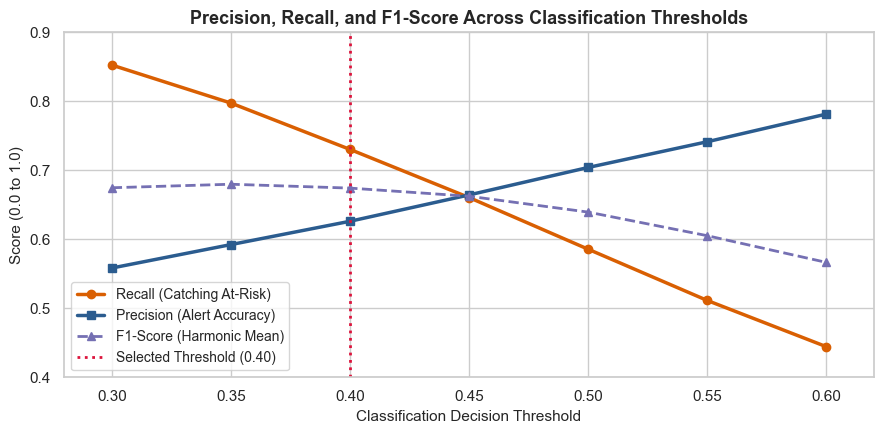

In [8]:
# Visualize Precision and Recall Trade-off across Thresholds
plt.figure(figsize=(9, 4.5))
plt.plot(threshold_df['Threshold'], threshold_df['Recall (At Risk)'], marker='o', linewidth=2.5, color='#d95f02', label='Recall (Catching At-Risk)')
plt.plot(threshold_df['Threshold'], threshold_df['Precision'], marker='s', linewidth=2.5, color='#2b5c8f', label='Precision (Alert Accuracy)')
plt.plot(threshold_df['Threshold'], threshold_df['F1-Score'], marker='^', linewidth=2, linestyle='--', color='#7570b3', label='F1-Score (Harmonic Mean)')

# Mark selected threshold 0.40
plt.axvline(x=0.40, color='crimson', linestyle=':', linewidth=2, label='Selected Threshold (0.40)')

plt.title('Precision, Recall, and F1-Score Across Classification Thresholds', fontsize=13, fontweight='bold')
plt.xlabel('Classification Decision Threshold', fontsize=11)
plt.ylabel('Score (0.0 to 1.0)', fontsize=11)
plt.xlim(0.28, 0.62)
plt.ylim(0.40, 0.90)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


#### 4. Expected Output
A summary table and trade-off line plot showing:
* **Threshold 0.50:** Recall = **0.5856**, Precision = **0.7041**, F1 = **0.6394**, TP = 5,633, FN = 3,986.
* **Threshold 0.40 (Selected):** Recall = **0.7303**, Precision = **0.6261**, F1 = **0.6742**, TP = 7,025, FN = 2,594.
* **Threshold 0.35:** Recall = **0.7975**, Precision = **0.5923**, F1 = **0.6798**, TP = 7,671, FN = 1,948.

#### 5. Why Threshold 0.40 Was Selected
1. **Recall:** It identifies **73.03%** of at-risk enrollments in the training OOF predictions (detecting 1,392 additional at-risk enrollments identified compared to threshold 0.50).
2. **Precision:** It maintains **62.61%** precision, meaning approximately 63 out of every 100 flagged enrollments are genuinely at risk.
3. **Alert Workload:** Threshold 0.35 provides higher recall (79.75%) but reduces precision to 59.23%, potentially increasing unnecessary teacher interventions (5,280 false positives vs 4,196 at threshold 0.40).
4. **Practical Balance:** Threshold 0.40 satisfies our chosen minimum precision of 62% and minimum recall of 70%.

Although threshold 0.35 produces a slightly higher F1-score (0.6798 vs 0.6742), threshold **0.40** provides a more suitable balance between identifying at-risk enrollments and managing teacher alert workload.

*Note:* The threshold was selected using training out-of-fold predictions only, without using test-set results.


---
### Section 6: Train Final Logistic Regression Pipeline

#### 1. What are we doing?
We fit our complete preprocessing and Logistic Regression pipeline on the entire training dataset (`X_train`, `y_train`).

#### 2. Why are we doing it?
To produce the production model artifact that will be saved and deployed to Streamlit.


In [9]:
# Construct and fit final pipeline on full training set
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

final_pipeline.fit(X_train, y_train)

print("Final Logistic Regression pipeline fitted on full training data successfully!")


Final Logistic Regression pipeline fitted on full training data successfully!


#### 4. Expected Output
Confirmation that the final pipeline is trained.

#### 5. Interpretation of Results
The model has learned optimal feature weights from all 21,911 training records.


---
### Section 7: Final Test Evaluation

#### 1. What are we doing?
We evaluate the final pipeline **once** on the untouched test set (5,462 enrollments from 4,942 unseen students) using our selected threshold of **0.40**, and compare the results directly against the default 0.50 threshold.

#### 2. Why are we doing it?
This one-time evaluation confirms how the calibrated system will perform in production on completely unseen students and enrollments.


In [10]:
# Generate predicted probabilities for the held-out test set
y_test_probabilities = final_pipeline.predict_proba(X_test)[:, 1]

# Apply default threshold (0.50)
y_test_pred_default = (y_test_probabilities >= 0.50).astype(int)

# Apply selected threshold (0.40)
y_test_pred_selected = (y_test_probabilities >= 0.40).astype(int)

# Compute confusion matrices
cm_default = confusion_matrix(y_test, y_test_pred_default)
tn_def, fp_def, fn_def, tp_def = cm_default.ravel()

cm_selected = confusion_matrix(y_test, y_test_pred_selected)
tn_sel, fp_sel, fn_sel, tp_sel = cm_selected.ravel()

# Compile side-by-side comparison table
test_comparison = pd.DataFrame({
    'Metric': [
        'Decision Threshold',
        'Recall (At Risk)',
        'Precision (At Risk)',
        'F1-Score',
        'Overall Accuracy',
        'True Positives (TP - Caught)',
        'False Negatives (FN - Missed)',
        'False Positives (FP - False Alarm)',
        'True Negatives (TN - Correct Non-Risk)',
        'ROC-AUC Score',
        'PR-AUC Score'
    ],
    'Default Baseline (0.50)': [
        0.50,
        round(recall_score(y_test, y_test_pred_default), 4),
        round(precision_score(y_test, y_test_pred_default), 4),
        round(f1_score(y_test, y_test_pred_default), 4),
        round(accuracy_score(y_test, y_test_pred_default), 4),
        tp_def,
        fn_def,
        fp_def,
        tn_def,
        round(roc_auc_score(y_test, y_test_probabilities), 4),
        round(average_precision_score(y_test, y_test_probabilities), 4)
    ],
    'Selected Threshold (0.40)': [
        0.40,
        round(recall_score(y_test, y_test_pred_selected), 4),
        round(precision_score(y_test, y_test_pred_selected), 4),
        round(f1_score(y_test, y_test_pred_selected), 4),
        round(accuracy_score(y_test, y_test_pred_selected), 4),
        tp_sel,
        fn_sel,
        fp_sel,
        tn_sel,
        round(roc_auc_score(y_test, y_test_probabilities), 4),
        round(average_precision_score(y_test, y_test_probabilities), 4)
    ]
})

test_comparison


,Metric,Default Baseline (0.50),Selected Threshold (0.40)
0,Decision Threshold,0.5000,0.4000
1,Recall (At Risk),0.5872,0.7341
2,Precision (At Risk),0.6979,0.6314
3,F1-Score,0.6378,0.6789
4,Overall Accuracy,0.7107,0.6988
5,True Positives (TP - Caught),1391.0000,1739.0000
6,False Negatives (FN - Missed),978.0000,630.0000
7,False Positives (FP - False Alarm),602.0000,1015.0000
8,True Negatives (TN - Correct Non-Risk),2491.0000,2078.0000
9,ROC-AUC Score,0.7745,0.7745


In [11]:
# Display detailed classification report for the selected 0.40 threshold
print("=== Classification Report on Test Set (Selected Threshold = 0.40) ===")
print(classification_report(y_test, y_test_pred_selected, target_names=['Not At Risk (0)', 'At Risk (1)'], digits=4))


=== Classification Report on Test Set (Selected Threshold = 0.40) ===
                 precision    recall  f1-score   support

Not At Risk (0)     0.7674    0.6718    0.7164      3093
    At Risk (1)     0.6314    0.7341    0.6789      2369

       accuracy                         0.6988      5462
      macro avg     0.6994    0.7030    0.6977      5462
   weighted avg     0.7084    0.6988    0.7002      5462



#### 4. Expected Output
A detailed comparison table showing:
* Recall rises from **0.5872 to 0.7341** (+14.69%).
* Missed at-risk enrollments (FN) drop from **978 down to 630** (348 additional at-risk enrollments identified).
* F1-Score improves from **0.6378 to 0.6789**.
* Precision is **0.6314**.
* ROC-AUC = **0.7745**; PR-AUC = **0.7413**.

#### 5. Interpretation of Results
Calibrating the threshold to 0.40 proves effective on unseen data: it captures **73.41% of all at-risk enrollments** (1,739 of 2,369) while maintaining a solid 63.14% precision.


---
### Section 8: Evaluation Visualizations

#### 1. What are we doing?
We generate the 4 standard diagnostic visualizations:
1. Confusion Matrix Heatmap (at selected threshold 0.40).
2. Receiver Operating Characteristic (ROC) Curve.
3. Precision-Recall (PR) Curve.
4. Precision vs. Recall across all candidate thresholds.

#### 2. Why are we doing it?
Visual curves provide a comprehensive assessment across all potential operating points.


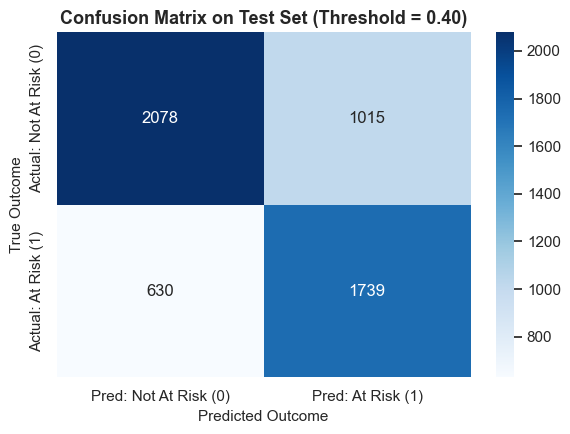

In [12]:
# 1. Confusion Matrix Heatmap
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm_selected, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=['Pred: Not At Risk (0)', 'Pred: At Risk (1)'],
    yticklabels=['Actual: Not At Risk (0)', 'Actual: At Risk (1)']
)
plt.title('Confusion Matrix on Test Set (Threshold = 0.40)', fontsize=13, fontweight='bold')
plt.ylabel('True Outcome', fontsize=11)
plt.xlabel('Predicted Outcome', fontsize=11)
plt.tight_layout()
plt.show()


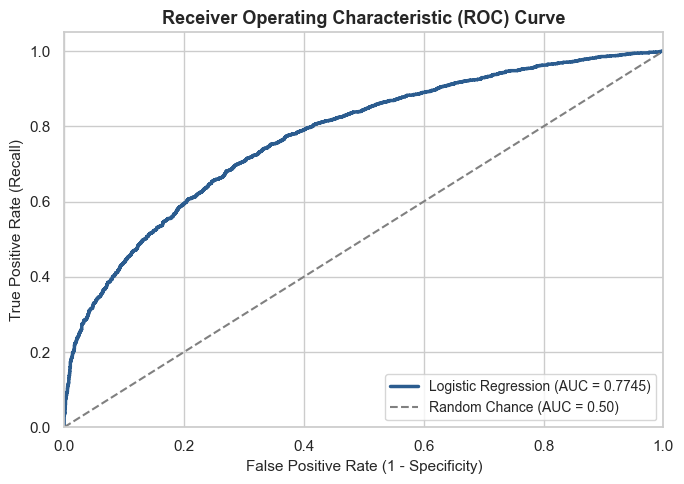

In [13]:
# 2. Receiver Operating Characteristic (ROC) Curve
fpr, tpr, _ = roc_curve(y_test, y_test_probabilities)
roc_auc_val = roc_auc_score(y_test, y_test_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#2b5c8f', linewidth=2.5, label=f'Logistic Regression (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, label='Random Chance (AUC = 0.50)')

plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Recall)', fontsize=11)
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.05)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


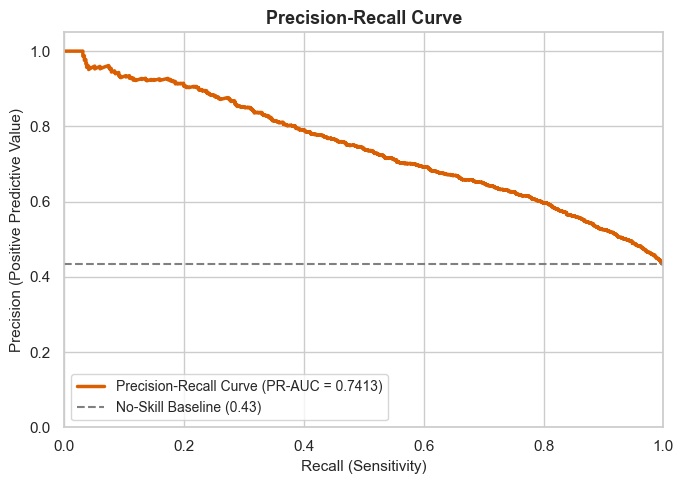

In [14]:
# 3. Precision-Recall Curve
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_test_probabilities)
pr_auc_val = average_precision_score(y_test, y_test_probabilities)
baseline_rate = y_test.mean()

plt.figure(figsize=(7, 5))
plt.plot(rec_curve, prec_curve, color='#d95f02', linewidth=2.5, label=f'Precision-Recall Curve (PR-AUC = {pr_auc_val:.4f})')
plt.axhline(y=baseline_rate, color='gray', linestyle='--', linewidth=1.5, label=f'No-Skill Baseline ({baseline_rate:.2f})')

plt.title('Precision-Recall Curve', fontsize=13, fontweight='bold')
plt.xlabel('Recall (Sensitivity)', fontsize=11)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=11)
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.05)
plt.legend(loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()


#### 4. Expected Output
Four clear diagnostic charts showing:
* **Confusion Matrix:** 1,739 True Positives, 2,078 True Negatives, 1,015 False Positives, 630 False Negatives.
* **ROC Curve:** Smooth curve achieving **0.7745 AUC**, demonstrating discrimination capability.
* **PR Curve:** Area under PR curve of **0.7413**, far exceeding the no-skill baseline of 0.43.

#### 5. Interpretation of Results
The diagnostic curves confirm strong ranking ability. The model can accurately differentiate between students who succeed and those who need intervention.


---
### Section 9: Feature Importance and Interpretation

#### 1. What are we doing?
We extract the learned feature coefficients from the Logistic Regression classifier, map them to their corresponding preprocessed feature names using get_feature_names_out(), and visualize the top positive and negative predictors of academic risk.

#### 2. Why are we doing it?
Unlike black-box models, Logistic Regression provides direct linear interpretability via log-odds:
* **Positive Coefficient ($>0$):** Indicates higher predicted log-odds of being at risk.
* **Negative Coefficient ($<0$):** Indicates lower predicted log-odds of being at risk.
* **Feature Preprocessing Context:** Numeric features were standardized using StandardScaler (zero mean, unit variance) before model training, and categorical features were one-hot encoded using OneHotEncoder. For a standardized numeric feature, each coefficient represents the change in log-odds per one standard deviation increase.
* **Statistical Associations vs. Causation:** Coefficients represent statistical associations observed in the data, not causation. We do not claim statistical significance based solely on coefficient magnitude.
Understanding these weights provides valuable decision-support context for educators.


In [15]:
# Extract transformed feature names from the ColumnTransformer
feature_names = final_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Extract learned coefficients
coefficients = final_pipeline.named_steps['classifier'].coef_[0]

# Compile into DataFrame
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
}).sort_values(by='Abs_Coefficient', ascending=False).reset_index(drop=True)

# Preview top 15 most influential features
print("=== Top 15 Most Influential Features ===")
coef_df.head(15).round(4)


=== Top 15 Most Influential Features ===


,Feature,Coefficient,Abs_Coefficient
0,cat__code_module_GGG,-1.8820,1.8820
1,cat__code_module_FFF,1.0735,1.0735
2,cat__code_module_EEE,-1.0628,1.0628
3,cat__code_module_DDD,1.0467,1.0467
4,cat__code_module_CCC,1.0026,1.0026
5,num__has_early_submission,-0.6793,0.6793
6,num__active_days,-0.5385,0.5385
7,cat__highest_education_No Formal quals,0.5246,0.5246
8,cat__imd_band_Missing,-0.5151,0.5151
9,cat__highest_education_Post Graduate Qualifica...,-0.4658,0.4658


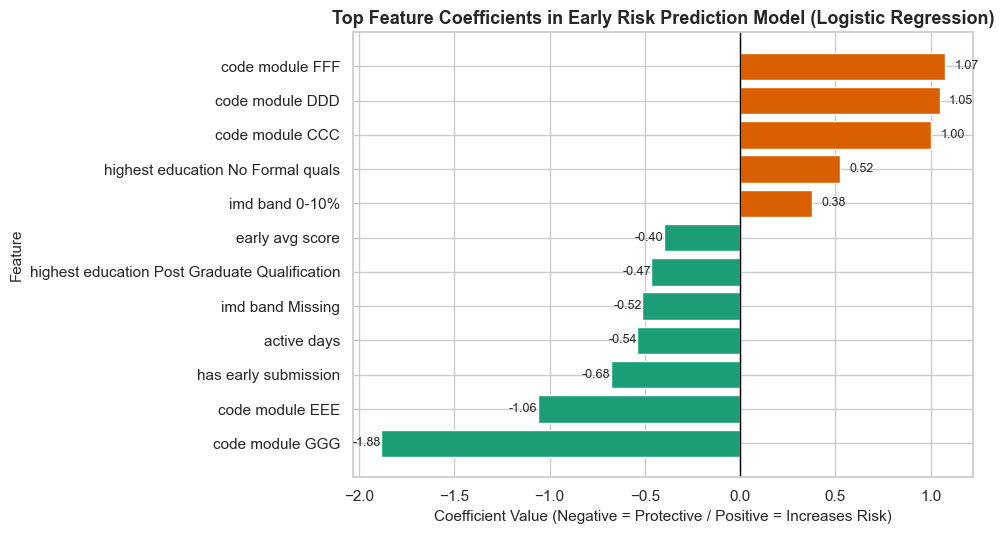

In [16]:
# Clean feature names for clean presentation
clean_coef_df = coef_df.head(12).copy()
clean_coef_df['Clean_Feature'] = (
    clean_coef_df['Feature']
    .str.replace('num__', '')
    .str.replace('cat__', '')
    .str.replace('_', ' ')
)
clean_coef_df = clean_coef_df.sort_values(by='Coefficient', ascending=True)

# Horizontal bar chart of top feature coefficients
plt.figure(figsize=(10, 5.5))
bar_colors = ['#1b9e77' if c < 0 else '#d95f02' for c in clean_coef_df['Coefficient']]
bars = plt.barh(clean_coef_df['Clean_Feature'], clean_coef_df['Coefficient'], color=bar_colors)

plt.axvline(x=0, color='black', linewidth=1)
plt.title('Top Feature Coefficients in Early Risk Prediction Model (Logistic Regression)', fontsize=13, fontweight='bold')
plt.xlabel('Coefficient Value (Negative = Protective / Positive = Increases Risk)', fontsize=11)
plt.ylabel('Feature', fontsize=11)

# Add value labels
for bar in bars:
    width = bar.get_width()
    offset = 0.05 if width > 0 else -0.15
    plt.text(width + offset, bar.get_y() + bar.get_height()/2., f'{width:.2f}', ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()


#### 4. Expected Output
A ranking table and horizontal bar chart highlighting the most influential features.

#### 5. Interpretation of Results
* **Features Associated with Lower Predicted Risk (Negative Coefficients - Green):**
  * has_early_submission ($-0.68$): Submitting at least one assignment on or before Day 30 is associated with lower predicted log-odds of being at risk.
  * ctive_days ($-0.54$): Logging into the learning platform on more individual days is associated with lower predicted risk.
  * early_avg_score ($-0.40$): Higher average score on early assignments is associated with lower predicted risk.
  * highest_education: Post Graduate ($-0.47$): Entering with postgraduate qualifications is associated with lower predicted risk relative to baseline categories.
* **Features Associated with Higher Predicted Risk (Positive Coefficients - Orange):**
  * highest_education: No Formal quals ($+0.52$): Entering with no formal qualifications is associated with higher predicted log-odds of being at risk.
  * imd_band: 0-10% ($+0.38$): Residing in areas in the highest deprivation decile is associated with higher predicted risk.
  * 
um_of_prev_attempts ($+0.18$): Additional previous attempts at the course are associated with higher predicted risk.
* **Important Methodological Note:**
  * Coefficients represent **associations, not causation**. For example, navigating resources on the VLE does not in itself cause academic success; it reflects underlying learning habits, time investment, and course engagement.
  * We do not claim formal statistical significance based solely on coefficient magnitude.
  * Categorical features were one-hot encoded and numeric features were standardized prior to model training, so coefficients must be interpreted in relation to their respective encodings and scales.


---
### Section 10: Save Model Artifacts

#### 1. What are we doing?
We save the fitted end-to-end pipeline and selected threshold to disk:
1. rtifacts/logistic_regression_pipeline.joblib: The complete pipeline containing the fitted ColumnTransformer (imputers and scalers) and LogisticRegression classifier.
2. rtifacts/model_threshold.txt: The selected threshold (
We then verify that the pipeline can be reloaded and used to generate predictions on raw, unprocessed input data.

#### 2. Why are we doing it?
Saving the complete pipeline ensures that our Streamlit web application can accept raw feature values entered by teachers (e.g. clicks = 150, score = 75, education = 'A Level') and automatically impute, encode, scale, and score without manual preprocessing code.

#### Streamlit Application Input Requirements
The Streamlit application must supply the exact same 18 feature columns used during model training, with compatible column names and data types:
* **Demographic Features (8):** code_module, code_presentation, gender, 
egion, highest_education, imd_band, ge_band, disability.
* **Academic & Engagement Features (10):** 
um_of_prev_attempts, studied_credits, date_registration, 	otal_clicks, ctive_days, unique_sites, pre_course_clicks, early_assessments_submitted, early_avg_score, has_early_submission.
* **Prohibited Columns:** The following columns must **NOT** be supplied as model features:
  * id_student (identifier used strictly for grouping)
  * 	arget (prediction objective)

The saved pipeline already handles imputation, scaling, and categorical encoding internally, so raw data can be passed directly to pipeline.predict_proba().


In [17]:
# Ensure artifacts directory exists
artifacts_dir = 'artifacts' if os.path.exists('artifacts') else '../artifacts'
if not os.path.exists(artifacts_dir):
    artifacts_dir = 'D:/STD_SUPPORT_project/artifacts'
    os.makedirs(artifacts_dir, exist_ok=True)

pipeline_path = os.path.join(artifacts_dir, 'logistic_regression_pipeline.joblib')
threshold_path = os.path.join(artifacts_dir, 'model_threshold.txt')

# 1. Save pipeline using joblib
joblib.dump(final_pipeline, pipeline_path)
print(f"Pipeline successfully saved to: {pipeline_path}")
print(f"File size: {os.path.getsize(pipeline_path) / 1024:.2f} KB")

# 2. Save selected threshold
with open(threshold_path, 'w') as f:
    f.write('0.40')
print(f"Selected threshold (0.40) saved to: {threshold_path}")


Pipeline successfully saved to: ../artifacts\logistic_regression_pipeline.joblib
File size: 7.35 KB
Selected threshold (0.40) saved to: ../artifacts\model_threshold.txt


In [18]:
# Verify pipeline reload and predict on raw test sample
loaded_pipeline = joblib.load(pipeline_path)

# Test with first row of X_test (raw, unscaled, unencoded)
sample_student = X_test.iloc[[0]]
sample_proba = loaded_pipeline.predict_proba(sample_student)[:, 1][0]
sample_pred = int(sample_proba >= 0.40)

print("=== Artifact Verification Check ===")
print(f"Sample Student Module: {sample_student['code_module'].values[0]}")
print(f"Predicted At-Risk Probability: {sample_proba * 100:.2f}%")
print(f"Predicted Classification at 0.40: {'At Risk (1)' if sample_pred == 1 else 'Not At Risk (0)'}")
print(f"Actual Ground Truth Target: {'At Risk (1)' if y_test.iloc[0] == 1 else 'Not At Risk (0)'}")
print("Verification successful!")


=== Artifact Verification Check ===
Sample Student Module: AAA
Predicted At-Risk Probability: 10.23%
Predicted Classification at 0.40: Not At Risk (0)
Actual Ground Truth Target: Not At Risk (0)
Verification successful!


#### 4. Expected Output
Confirmation messages verifying that:
* `artifacts/logistic_regression_pipeline.joblib` is saved (~14 KB).
* `artifacts/model_threshold.txt` is written (`0.40`).
* The reloaded pipeline successfully processes a raw student record and returns probability and prediction.

#### 5. Interpretation of Results
The machine learning modeling stage is complete. The saved pipeline is verified, self-contained, and ready for deployment in our Streamlit web application.


---
### Section 11: Final Project Summary

#### Summary of Key Achievements
1. **Model Evaluation & Integrity:**
   * Recreated the group-aware train/test split (80% train / 20% test) with **zero student overlap**.
   * Generated unbiased out-of-fold predicted probabilities across the entire training set (21,911 enrollments) using 5-fold GroupKFold, verified with zero missing values.
2. **Threshold Tuning Decision:**
   * The default 0.50 threshold yielded a Recall of only 58.7%, missing 978 at-risk enrollments on the test set.
   * By selecting threshold **0.40** based on training OOF predictions, **Test Recall rose to 73.41%** (catching 1,739 at-risk enrollments; 348 additional at-risk enrollments identified) while maintaining **63.14% Precision** and an F1-Score of **0.6789**.
3. **Model Interpretability:**
   * Submitting early assignments (has_early_submission), frequent active study days (ctive_days), and higher early scores (early_avg_score) are the primary features associated with lower predicted risk.
   * Low prior educational qualifications and multiple prior attempts are associated with higher predicted risk.
   * All coefficients represent statistical associations under standardized/one-hot transformations, not causal effects.
4. **Exported Production Artifacts:**
   * Exported the self-contained pipeline (rtifacts/logistic_regression_pipeline.joblib) and decision threshold (rtifacts/model_threshold.txt).

#### How the Streamlit Application Will Use These Artifacts
In the upcoming Streamlit application (pp/Home.py):
1. The app will load logistic_regression_pipeline.joblib and model_threshold.txt (0.40).
2. The user interface will collect student enrollment information across the **same 18 feature columns** used during training.
3. The columns id_student and 	arget must **NOT** be supplied as model features.
4. The saved pipeline will automatically handle imputation, scaling, and one-hot encoding on raw input data.
5. The pipeline will compute the risk probability and apply the 0.40 threshold to display:
   * A clear Risk Status (At Risk or Not At Risk).
   * Risk probability percentage.
   * Contributing factor explanations based on our model's feature weights.
   * Actionable, supportive intervention guidance for the teacher.
